In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Загружаем сырые данные
df_raw = pd.read_csv("../data/raw/train.csv", parse_dates=["date"])

# 2. Оставляем один магазин (например, store=1) и первые 5 товаров, 
# чтобы графики были читаемыми, а данных для обучения хватило
df_filtered = df_raw[(df_raw["store"] == 1) & (df_raw["item"].isin([1, 2, 3, 4, 5]))].copy()

# 3. Агрегируем продажи до месячного уровня
df_filtered["month"] = df_filtered["date"].dt.to_period("M")
df_monthly = df_filtered.groupby(["month", "item"])["sales"].sum().reset_index()

# 4. Приводим к нужному формату (date, product, demand_tons)
df_monthly["date"] = df_monthly["month"].dt.to_timestamp()
df_monthly["product"] = "Item_" + df_monthly["item"].astype(str)
df_monthly["demand_tons"] = df_monthly["sales"]

# 5. Оставляем только нужные колонки и сохраняем в переменную df
df = df_monthly[["date", "product", "demand_tons"]]

df.head()

,date,product,demand_tons
0,2013-01-01,Item_1,328
1,2013-01-01,Item_2,911
2,2013-01-01,Item_3,547
3,2013-01-01,Item_4,346
4,2013-01-01,Item_5,276


Общая информация:

In [6]:
df.info()
df.describe()
df["product"].value_counts()
df.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         300 non-null    datetime64[us]
 1   product      300 non-null    str           
 2   demand_tons  300 non-null    int64         
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 8.9 KB


date           0
product        0
demand_tons    0
dtype: int64

График по каждой группе товаров:

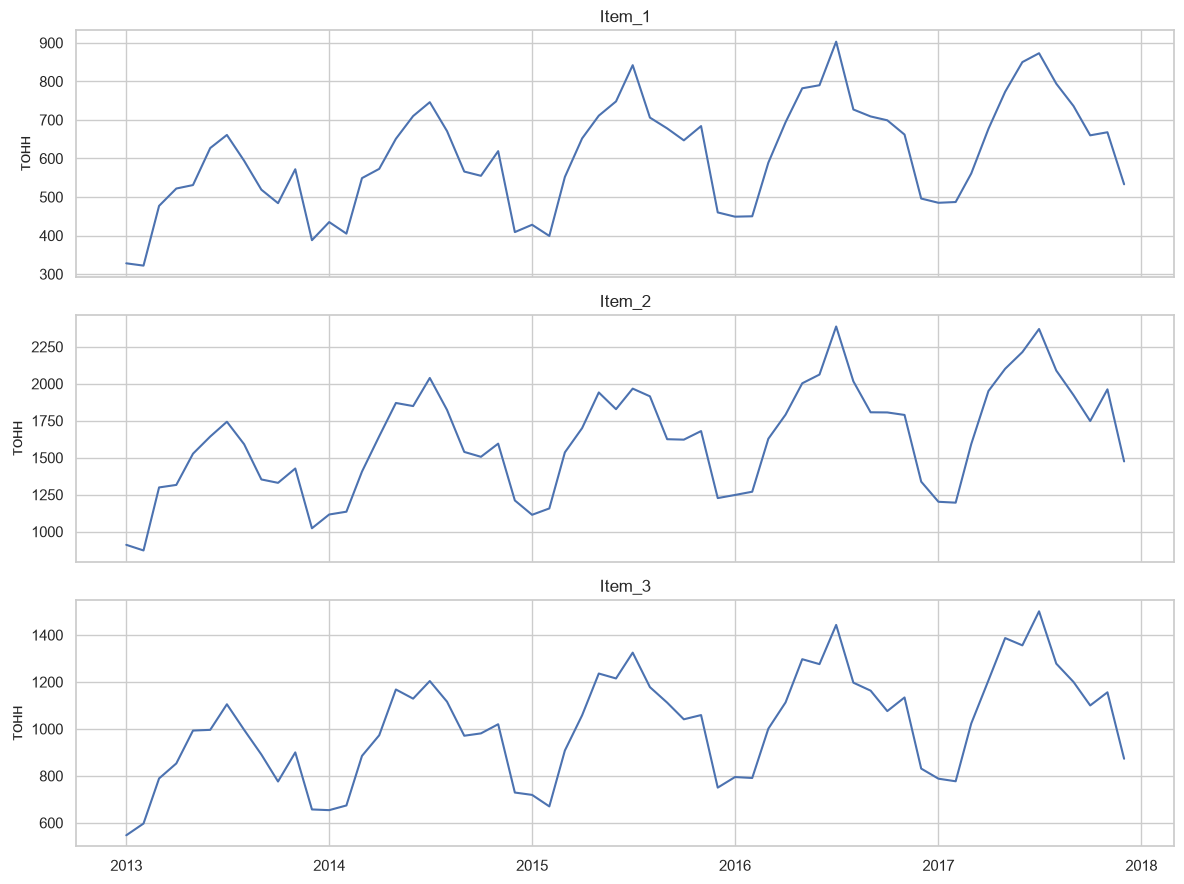

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, prod in zip(axes, df["product"].unique()):
    sub = df[df["product"] == prod]
    ax.plot(sub["date"], sub["demand_tons"])
    ax.set_title(prod)
    ax.set_ylabel("тонн")
plt.tight_layout()
plt.show()

Построение сезонного профиля:

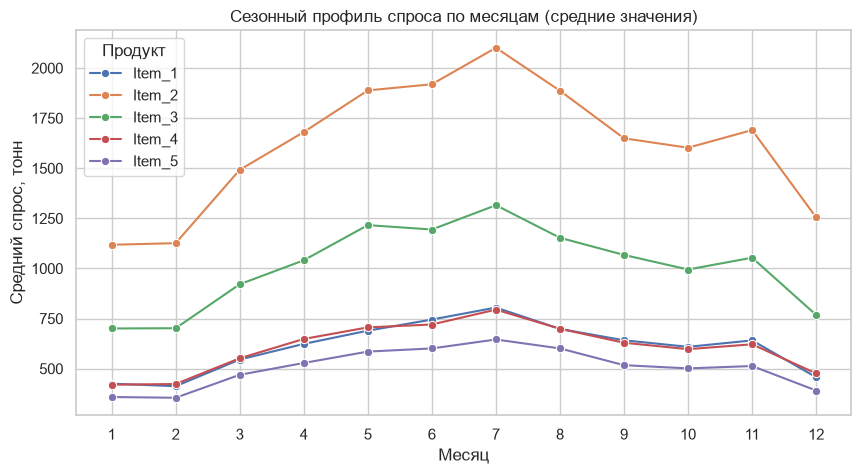

In [8]:
# Извлекаем номер месяца для анализа сезонности
df["month"] = df["date"].dt.month

# Считаем средние продажи по каждому товару для каждого месяца
season = df.groupby(["product", "month"])["demand_tons"].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=season, x="month", y="demand_tons", hue="product", marker="o")
plt.title("Сезонный профиль спроса по месяцам (средние значения)")
plt.xticks(range(1, 13))
plt.xlabel("Месяц")
plt.ylabel("Средний спрос, тонн")
plt.legend(title="Продукт")
plt.show()

Автокорреляция (ACF и PACF):

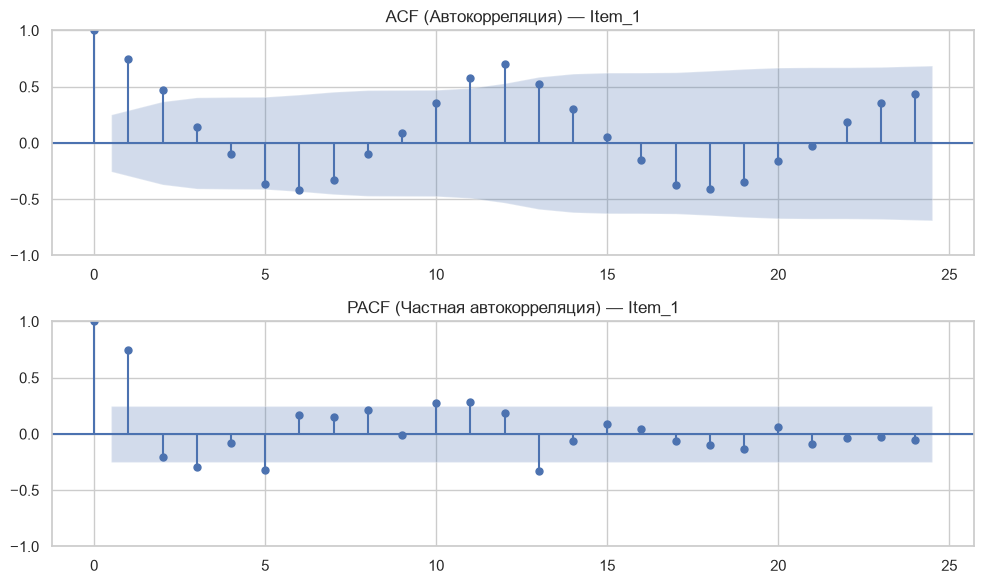

In [9]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Возьмем для примера один товар (Item_1)
sub = df[df["product"] == "Item_1"].set_index("date")["demand_tons"]

fig, ax = plt.subplots(2, 1, figsize=(10, 6))

plot_acf(sub, lags=24, ax=ax[0])
ax[0].set_title("ACF (Автокорреляция) — Item_1")

plot_pacf(sub, lags=24, ax=ax[1])
ax[1].set_title("PACF (Частная автокорреляция) — Item_1")

plt.tight_layout()
plt.show()

Сохранение результата:

In [10]:
import os
os.makedirs("../data/processed", exist_ok=True)

# Сохраняем очищенный датафрейм
df.to_csv("../data/processed/demand_real.csv", index=False)
print("Данные успешно сохранены в ../data/processed/demand_real.csv")

Данные успешно сохранены в ../data/processed/demand_real.csv
